In [7]:
# Q1 Part 1: Data Loading & Initial Inspection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [8]:
# Load Dataset
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

In [4]:
# Display First 5 Rows
print(df.head())

      id  gender   age  hypertension  heart_disease ever_married  \
0   9046    Male  67.0             0              1          Yes   
1  51676  Female  61.0             0              0          Yes   
2  31112    Male  80.0             0              1          Yes   
3  60182  Female  49.0             0              0          Yes   
4   1665  Female  79.0             1              0          Yes   

       work_type Residence_type  avg_glucose_level   bmi   smoking_status  \
0        Private          Urban             228.69  36.6  formerly smoked   
1  Self-employed          Rural             202.21   NaN     never smoked   
2        Private          Rural             105.92  32.5     never smoked   
3        Private          Urban             171.23  34.4           smokes   
4  Self-employed          Rural             174.12  24.0     never smoked   

   stroke  
0       1  
1       1  
2       1  
3       1  
4       1  


In [5]:
# Dataset Information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   str    
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   str    
 6   work_type          5110 non-null   str    
 7   Residence_type     5110 non-null   str    
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   str    
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 634.7 KB


In [6]:
# Statistical Summary
print(df.describe())

                 id          age  hypertension  heart_disease  \
count   5110.000000  5110.000000   5110.000000    5110.000000   
mean   36517.829354    43.226614      0.097456       0.054012   
std    21161.721625    22.612647      0.296607       0.226063   
min       67.000000     0.080000      0.000000       0.000000   
25%    17741.250000    25.000000      0.000000       0.000000   
50%    36932.000000    45.000000      0.000000       0.000000   
75%    54682.000000    61.000000      0.000000       0.000000   
max    72940.000000    82.000000      1.000000       1.000000   

       avg_glucose_level          bmi       stroke  
count        5110.000000  4909.000000  5110.000000  
mean          106.147677    28.893237     0.048728  
std            45.283560     7.854067     0.215320  
min            55.120000    10.300000     0.000000  
25%            77.245000    23.500000     0.000000  
50%            91.885000    28.100000     0.000000  
75%           114.090000    33.100000     0

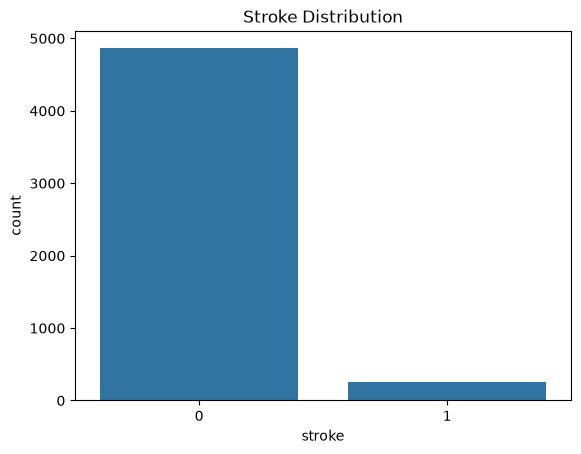

In [9]:
# Q2 Part 2: Exploratory Data Analysis & Visualization

# Q1: Stroke Countplot
sns.countplot(data=df, x='stroke')
plt.title("Stroke Distribution")
plt.show()

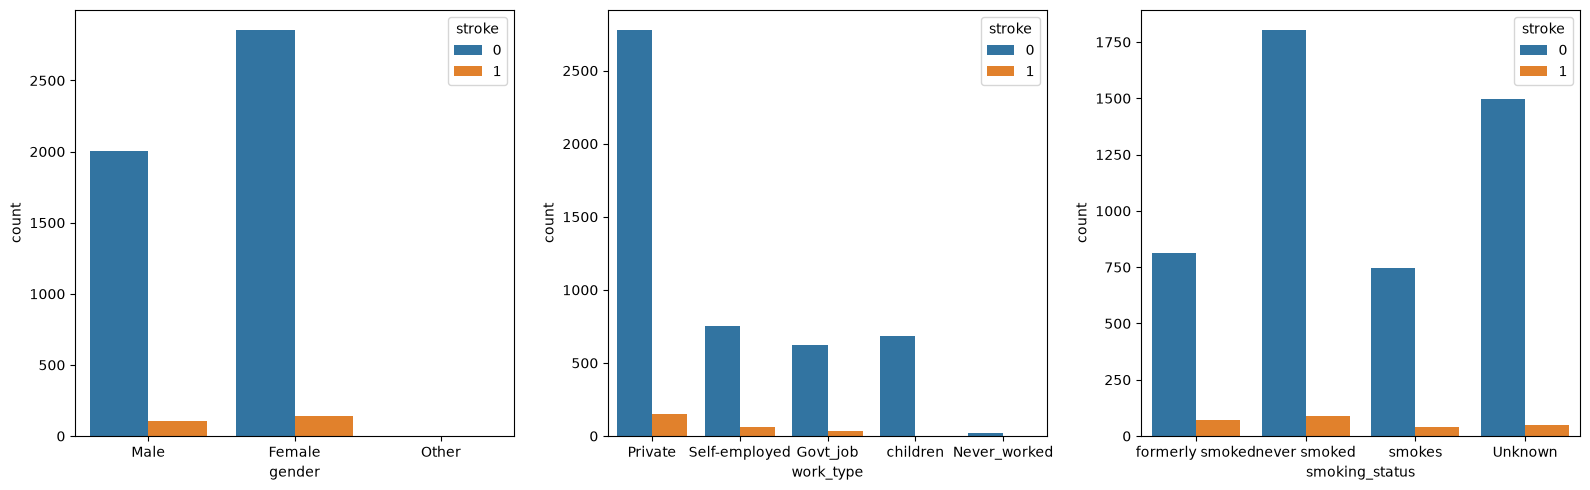

In [10]:
# Q2: Countplots with Stroke
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

sns.countplot(data=df, x='gender', hue='stroke', ax=ax[0])
sns.countplot(data=df, x='work_type', hue='stroke', ax=ax[1])
sns.countplot(data=df, x='smoking_status', hue='stroke', ax=ax[2])

plt.tight_layout()
plt.show()


In [13]:
# Q3: Drop Other Gender
df = df[df['gender'] != 'Other']


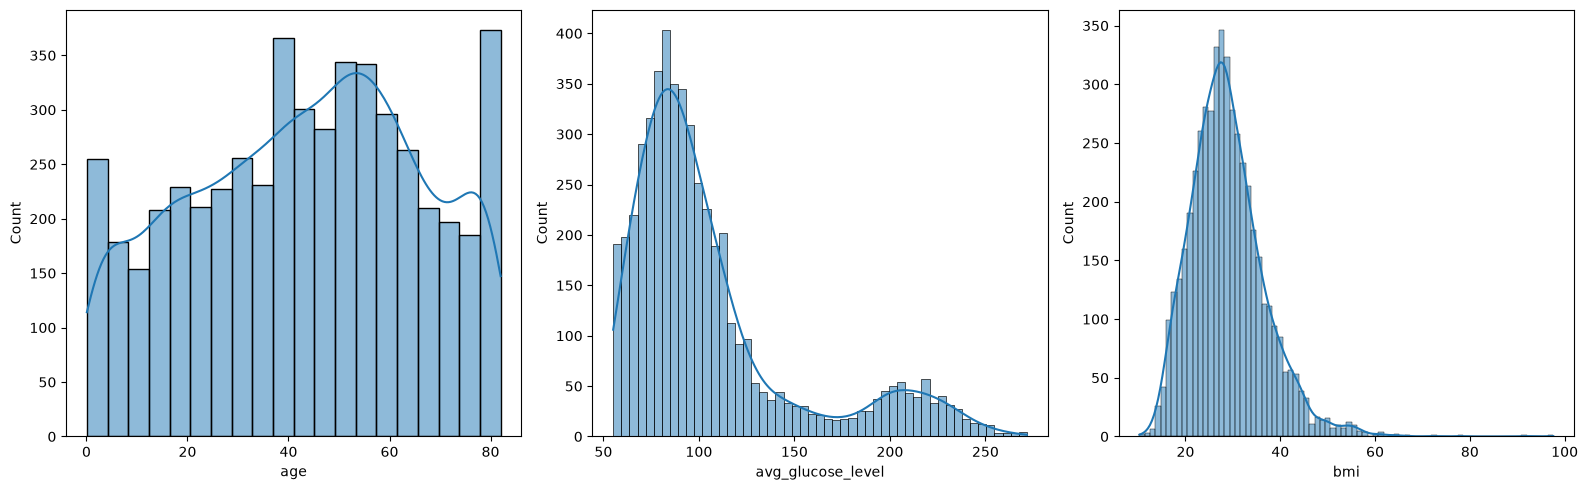

In [12]:
# Q4: Histograms and KDE
fig, ax = plt.subplots(1, 3, figsize=(16, 5))

sns.histplot(data=df, x='age', kde=True, ax=ax[0])
sns.histplot(data=df, x='avg_glucose_level', kde=True, ax=ax[1])
sns.histplot(data=df, x='bmi', kde=True, ax=ax[2])

plt.tight_layout()
plt.show()

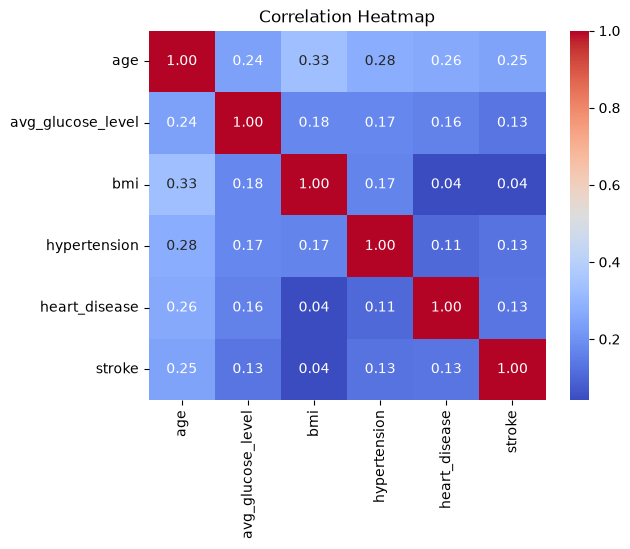

In [14]:
# Q5: Correlation Heatmap
a = ['age', 'avg_glucose_level', 'bmi', 'hypertension',
     'heart_disease', 'stroke']

b = df[a].corr()

sns.heatmap(b, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.show()

In [15]:
# Q3 Part 3: Data Preprocessing (Cleaning)

# Check Missing Values
print(df.isnull().sum())

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [16]:
# Fill Missing BMI Values
df['bmi'] = df['bmi'].fillna(df['bmi'].median())


In [17]:
# Verify Missing Values
print(df.isnull().sum())

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64


In [18]:
# Check and Remove Duplicates
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicates: 0


In [19]:
# Drop ID Column
df = df.drop('id', axis=1)

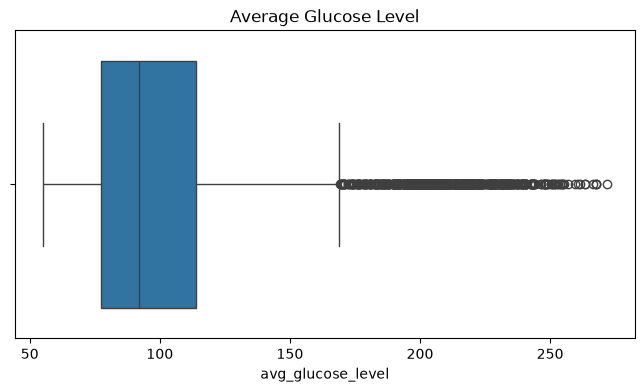

In [20]:
# Boxplot for Outliers
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['avg_glucose_level'])
plt.title("Average Glucose Level")
plt.show()

In [21]:
# Q4 Part 4: Feature Transformation

# Reset Index
df = df.reset_index(drop=True)

In [22]:
# One-Hot Encoding
df = pd.get_dummies(df, columns=[
    'gender',
    'work_type',
    'smoking_status',
    'ever_married',
    'Residence_type'
], dtype=int)

In [23]:
# Display Data
print(df.head())

    age  hypertension  heart_disease  avg_glucose_level   bmi  stroke  \
0  67.0             0              1             228.69  36.6       1   
1  61.0             0              0             202.21  28.1       1   
2  80.0             0              1             105.92  32.5       1   
3  49.0             0              0             171.23  34.4       1   
4  79.0             1              0             174.12  24.0       1   

   gender_Female  gender_Male  work_type_Govt_job  work_type_Never_worked  \
0              0            1                   0                       0   
1              1            0                   0                       0   
2              0            1                   0                       0   
3              1            0                   0                       0   
4              1            0                   0                       0   

   ...  work_type_Self-employed  work_type_children  smoking_status_Unknown  \
0  ...             

In [24]:
# Display Columns
print(df.columns)

Index(['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi',
       'stroke', 'gender_Female', 'gender_Male', 'work_type_Govt_job',
       'work_type_Never_worked', 'work_type_Private',
       'work_type_Self-employed', 'work_type_children',
       'smoking_status_Unknown', 'smoking_status_formerly smoked',
       'smoking_status_never smoked', 'smoking_status_smokes',
       'ever_married_No', 'ever_married_Yes', 'Residence_type_Rural',
       'Residence_type_Urban'],
      dtype='str')


In [29]:
# Q5 Part 5: Data Splitting

from sklearn.model_selection import train_test_split


In [31]:
# Separate Features and Target
X = df.drop('stroke', axis=1)
y = df['stroke']

In [32]:
# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [33]:
# Check Shapes
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4087, 20)
X_test: (1022, 20)
y_train: (4087,)
y_test: (1022,)


In [34]:
# Q6 Part 6: Feature Scaling

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()

In [35]:
col = ['age', 'avg_glucose_level', 'bmi']

In [36]:
X_train[col] = sc.fit_transform(X_train[col])

X_test[col] = sc.transform(X_test[col])

print("Training Data:")
print(X_train[col].head())

print("\nTesting Data:")
print(X_test[col].head())

Training Data:
           age  avg_glucose_level       bmi
802   1.588594           0.142703 -0.048907
3926  0.836881          -0.392719  0.957224
2337 -0.976075          -1.026771  0.621847
3909 -0.533891          -0.890714  0.196176
1886 -0.533891          -1.024350 -1.158232

Testing Data:
           age  avg_glucose_level       bmi
4687 -0.533891          -0.909428 -0.758359
4477 -0.135925          -0.899741 -0.074706
3520  0.394696           0.107478  0.144579
4354  1.588594          -0.649862 -1.209828
3825  1.411720          -0.250717 -0.216596


In [37]:
# Q7 Part 7: Handling Class Imbalance

from imblearn.over_sampling import SMOTE


In [38]:
# Check Distribution
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
stroke
0    3900
1     187
Name: count, dtype: int64


In [39]:
# Apply SMOTE
sm = SMOTE(random_state=42)
X_train, y_train = sm.fit_resample(X_train, y_train)


In [40]:
# Verify Distribution
print("\nAfter SMOTE:")
print(y_train.value_counts())


After SMOTE:
stroke
0    3900
1    3900
Name: count, dtype: int64


In [41]:
#1. High-Risk Stroke Patient Persona

# Name: Bari
# Age: 70 years
# Gender: Male

# Health Profile:

# Has hypertension.

# Has a high average glucose level.

# Has a high BMI.

# Has a history of smoking.

# Has a higher risk of stroke due to age and health conditions.

# 2. Summary of Findings

# The dataset shows that most patients did not experience a stroke.

# Stroke cases are much fewer than non-stroke cases, indicating class imbalance.

# Age, glucose level, and BMI are important health features to investigate.

# Data preprocessing helped handle missing values, duplicates, and outliers.

# Categorical features were converted into numerical values using One-Hot Encoding.

# SMOTE was used to balance the training data